# Tangent-Bundle Splitting Diffusion on Manifolds — a guided demo

This notebook is a reader-facing introduction to the **tangent-bundle splitting**
generative framework for Riemannian manifolds. It is organized as four
self-contained demonstrations:

1. **Correctness on the flat torus $T^2$, from a single point.** The forward
   chain converges to the invariant law $\pi=\mathrm{Uniform}(x)\times\mathcal N(0,\sigma^2 I)(v)$,
   and the analytic (vertical) score is **regular** at every interval endpoint.
2. **Correctness of the training objective on $T^2$, from a GMM.** The analytic
   score generates correct samples (training-free), and the DSM training objective
   is an **unbiased estimator** of the analytic score.
3. **Non-Euclidean / non-orientable manifolds train:** Klein bottle and $\mathbb{RP}^2$.
4. **Non-compact manifolds train:** hyperbolic space $H^2$ (with a confining potential).

Each part stands alone. Parts 1–2 are *analytic* (seconds); parts 3–4 run short
trainings as smoke demonstrations.

Correspondence with the paper: Part 1 produces Fig. 2 (`sp_t2_*.pdf`), Part 2
produces Fig. 3 (`gmm_t2_*.pdf`), Parts 3–4 produce Fig. 4 (`klein_*`, `rp2_*`,
`h2_*.pdf`). Run the notebook from the repository root (or from `analysis/`).

In [1]:
import os, math, time, sys
# work from the repository root; make the package and analysis/ importable
ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "analysis" else os.getcwd()
os.chdir(ROOT)
sys.path[:0] = [ROOT, os.path.join(ROOT, "analysis")]
import numpy as np
# geomstats' numpy backend imports `trapz`, removed in recent numpy -> shim it.
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid
import torch
os.environ.setdefault("GEOMSTATS_BACKEND", "pytorch")
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)
TWO_PI = 2 * math.pi
def wrap(a):  # wrap angles to [-pi, pi)
    return (a + math.pi) % TWO_PI - math.pi

device: cuda:0 | torch 2.14.0+cu126


## Part 1 — Correctness on $T^2$ from a single point: invariant convergence + score regularity

On the flat torus the exponential map and the forward kernel are **exact**, so
this isolates the splitting scheme from any geometric approximation. We take the
dataset to be **one single point** at the origin, $p_0=\delta(x)$, and verify two
things:

* **(a) Convergence to the invariant law.** Running the forward chain from the
  single point to the terminal time, the joint $(x,v)$ law converges to
  $\pi=\mathrm{Uniform}(x)\times\mathcal N(0,\sigma^2 I)(v)$ — the stationary law
  of the continuous kinetic-Langevin SDE $dx=v\,dt,\ dv=-v\,dt+\sqrt2\,\sigma\,dW$.
  We measure this by the total-variation distance on the **full tangent-bundle
  product space** $(x_1,x_2,v_1,v_2)$, which drops to the invariant self-floor.
* **(b) Regularity of the score.** With a single point the forward kernel is a
  single Gaussian, so the vertical score $\nabla_v\log p_{n,\delta}$ is available
  in closed form. It stays **finite at every interval endpoint** ($\delta\to0$);
  only the single-sample DSM *label* has diverging variance there.

Each figure is saved *untitled* as a standalone PDF under `figures/` (captions in
LaTeX).

In [ ]:
from manifolds.torus import TorusManifold
from dynamics.splitting_sde import SplittingSDE

os.makedirs("figures", exist_ok=True)
class _Opt: pass

# Forward splitting sampler from a SINGLE POINT at the origin, keeping the WHOLE
# trajectory x_t, v_t at every grid time (for the TV-vs-time curve).
def run_forward_single_point(sigma, T=10.0, interval=40, N=20000, seed=0):
    torch.manual_seed(seed)
    man = TorusManifold(dim=2); man.sigma = sigma
    opt = _Opt(); opt.device = DEVICE; opt.T = T; opt.interval = interval
    opt.train_ts = torch.linspace(0, T, interval + 1, device=DEVICE)
    opt.eval_refine = 16; opt.infer_ode = False; opt.sample_bs = 300000
    opt.friction_gammas = torch.full((interval,), 1.0, device=DEVICE)
    sde = SplittingSDE(opt, man)
    x0 = torch.zeros(N, 2, device=DEVICE)          # single point: delta at origin
    v0 = man.get_noise(x0)                          # v ~ N(0, sigma^2)
    xtraj, vtraj = sde.sample_forward_trajectory(x0, v0)   # (N, interval+1, 2)
    ts = opt.train_ts.cpu().numpy()
    return (wrap(xtraj.to(DEVICE)).cpu().numpy(), vtraj.cpu().numpy(), ts)

SIGMA = 1.0 / math.sqrt(2.0)   # T^2 auto value

# Joint TV on the FULL tangent-bundle product space (x_1,x_2,v_1,v_2):
# x on [-pi,pi]^2, v on [-VB,VB]^2 (VB=4*sigma covers N(0,sigma^2)). Measures
# convergence of the JOINT law to pi = Uniform(x) x N(0,sigma^2)(v).
VB = 4.0 * SIGMA
_RANGE = [[-math.pi, math.pi], [-math.pi, math.pi], [-VB, VB], [-VB, VB]]
def tv_bundle(A, B, bins=12):
    hA, _ = np.histogramdd(A, bins=bins, range=_RANGE)
    hB, _ = np.histogramdd(B, bins=bins, range=_RANGE)
    return 0.5 * np.abs(hA / hA.sum() - hB / hB.sum()).sum()

def sample_pi(n, rng):
    x = (rng.random((n, 2)) * 2 - 1) * math.pi
    v = SIGMA * rng.standard_normal((n, 2))
    return np.concatenate([x, v], axis=1)

xtraj, vtraj, ts = run_forward_single_point(SIGMA)
x0pt = xtraj[:, 0, :]; xT = xtraj[:, -1, :]; vT = vtraj[:, -1, :]
N = len(xT)

rng = np.random.default_rng(0)
ref_pi = sample_pi(N, rng)
pi_A = sample_pi(N, rng); pi_B = sample_pi(N, rng)
pi_floor = tv_bundle(pi_A, pi_B)
bundleT = np.concatenate([xT, vT], axis=1)
print(f"sigma = {SIGMA:.4f}  N = {N}  T = {ts[-1]:.1f}  bundle self-floor TV = {pi_floor:.4f}")
print(f"TV((x_T,v_T), pi) = {tv_bundle(bundleT, ref_pi):.4f}   Var(v_T) = {float((vT**2).mean()):.4f}  (sigma^2={SIGMA**2:.4f})")

In [ ]:
# ---- common bare-figure style (no titles; paper adds captions in LaTeX) ----
def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    print(f"saved figures/{name}.pdf")

# FIGURE A1 — convergence: joint tangent-bundle TV((x_t,v_t), pi) vs time -> floor
tv_t = np.array([tv_bundle(np.concatenate([xtraj[:, k, :], vtraj[:, k, :]], axis=1), ref_pi)
                 for k in range(xtraj.shape[1])])
fig, a = plt.subplots(figsize=(4.2, 3.2))
a.plot(ts, tv_t, "-o", color="seagreen", ms=3.5, lw=1.6, label=r"TV$\,((x_t,v_t),\,\pi)$")
a.axhline(pi_floor, color="0.4", ls="--", lw=1.2, label="invariant self-floor")
a.set_xlabel(r"time $t$"); a.set_ylabel(r"TV$\,((x_t,v_t),\,\pi)$")
a.set_ylim(0, None); a.legend(frameon=False, fontsize=9)
save(fig, "sp_t2_tv_vs_time"); plt.show()

**(b) Score regularity.** With the single point realized as a single
Gaussian mode (vanishing covariance $10^{-3} I$ at the origin), the forward kernel
is one Gaussian and the vertical score is closed form. We sweep the absolute time
$t$ across *every* interval and plot (left) the analytic score magnitude and
(right) the single-sample label RMS. Light vertical lines mark interval endpoints
($\delta\to0$).

In [ ]:
from splitting_target_kernel_t2 import SplittingTargetKernelT2
from dsm_momentum_kernel_t2 import DsmMomentumKernelT2, van_loan_continuous

# single point at the origin -> ONE Gaussian mode with a VANISHING covariance
# c = 1e-14 (numerical stand-in for delta(x)); larger c would regularize away the
# small-time behaviour we want to expose. Closed-form scores for both kernels.
C_PT = 1e-14     # regularization only acts below t ~ 3e-5, left of the plotted range
mus = np.array([[0.0, 0.0]]); covs = np.stack([np.eye(2) * C_PT]); weights = np.array([1.0])
T2, INTERVAL2 = 10.0, 40; H = T2 / INTERVAL2
ker_sp = SplittingTargetKernelT2(mus, covs, weights, sigma=SIGMA,
                                 T=T2, interval=INTERVAL2, n_images=2, device=DEVICE)
# DSM-momentum reference: continuous ONE-SHOT kinetic-Langevin kernel from the
# data endpoint to absolute time t (no interval structure).
ker_mom = DsmMomentumKernelT2(mus, covs, weights, sigma=SIGMA,
                              T=T2, interval=INTERVAL2, n_images=2, device=DEVICE)

# Score size measured where it matters: RMS of grad_v log p_t over samples
# (x,v) ~ p_t itself, i.e. sqrt(E_{p_t} ||grad_v log p_t||^2).
torch.manual_seed(0); B = 4000
def _draw(m, P, w):
    idx = torch.multinomial(w, B, replacement=True)
    z = torch.randn(B, 4, device=DEVICE, dtype=P.dtype)
    s = m[idx] + torch.einsum("bij,bj->bi", torch.linalg.cholesky(P[idx]), z)
    return wrap(s[:, :2]), s[:, 2:]
def rms_sp(n, d):
    x, v = _draw(*ker_sp.joint_gaussians(n, d), ker_sp.w)
    return float(ker_sp.vertical_score(x, v, n, d).pow(2).sum(1).mean().sqrt())
def rms_mom(t):
    x, v = _draw(*ker_mom.joint_gaussians(t), ker_mom.w)
    return float(ker_mom.vertical_score(x, v, t).pow(2).sum(1).mean().sqrt())

# time grid inside EVERY interval: log-spaced sub-steps delta in (1e-4, h] (resolves
# t -> 0 and each left endpoint t_n^+) plus a uniform fill of the interior.
deltas = np.unique(np.concatenate([np.logspace(-4, np.log10(H), 20),
                                   np.linspace(0, H, 11)[1:]]))
grid = [(n, float(d)) for n in range(INTERVAL2) for d in deltas]
t_abs = np.array([n * H + d for n, d in grid])

# FIGURE A2 — target score RMS vs time: splitting vs DSM-momentum
score_sp = np.array([rms_sp(n, d) for n, d in grid])
score_mom = np.array([rms_mom(t) for t in t_abs])
fig, a = plt.subplots(figsize=(4.2, 3.2))
a.plot(t_abs, score_sp, "-", color="seagreen", lw=1.4, label="splitting")
a.plot(t_abs, score_mom, "--", color="darkorange", lw=1.6, label="DSM-momentum")
for k in range(INTERVAL2 + 1): a.axvline(k * H, color="0.88", lw=0.5, zorder=0)
a.set_yscale("log"); a.set_xlim(-0.02 * T2, T2)   # small left margin: t->0 rise not hidden by spine
a.set_xlabel(r"time $t$"); a.set_ylabel(r"$\mathbb{E}_{p_t}[\|\nabla_v\log p_t\|^2]^{1/2}$")
a.legend(frameon=False, fontsize=9)
save(fig, "sp_t2_score_vs_t"); plt.show()

# FIGURE A3 — single-sample DSM label RMS vs time (TRUE-score convention).
#  splitting: local OU sub-step, per-coord std 1/(sigma*sigxi(delta)) -> diverges
#             at EVERY interval left endpoint.
#  DSM-momentum: the label conditions on the data endpoint (x_0, v_0): per-coord
#             std 1/(sigma*L_vv(t)), L_vv^2 = S_vv - S_xv^2/S_xx of the van Loan
#             transition cov -> diverges once, as t -> 0 (L_vv^2 ~ t/2).
def lvv(t):   # cancellation-safe closed form (gamma=1)
    em1, em2 = math.expm1(-t), math.expm1(-2 * t)
    s_xx = 2 * t + 4 * em1 - em2
    s_xv = em1 ** 2
    s_vv = -em2
    return math.sqrt(max(s_vv - s_xv ** 2 / s_xx, 1e-300))
lab_sp = np.array([math.sqrt(2) / (SIGMA * math.sqrt(-math.expm1(-2 * d))) for _, d in grid])
lab_mom = np.array([math.sqrt(2) / (SIGMA * lvv(t)) for t in t_abs])
fig, a = plt.subplots(figsize=(4.2, 3.2))
a.plot(t_abs, lab_sp, "-", color="crimson", lw=1.0, label="splitting")
a.plot(t_abs, lab_mom, "--", color="darkorange", lw=1.6, label="DSM-momentum")
for k in range(INTERVAL2 + 1): a.axvline(k * H, color="0.88", lw=0.5, zorder=0)
a.set_yscale("log"); a.set_xlim(-0.02 * T2, T2)   # small left margin: t->0 rise not hidden by spine
a.set_xlabel(r"time $t$"); a.set_ylabel("single-sample label RMS")
a.legend(frameon=False, fontsize=9)
save(fig, "sp_t2_label_rms_vs_t"); plt.show()

for n in [0, 1, 2, 5]:
    sel = [i for i, (k, _) in enumerate(grid) if k == n]
    print(f"splitting interval n={n}: score RMS over delta in [1e-4,h] = "
          f"[{score_sp[sel].min():.3g}, {score_sp[sel].max():.3g}]")
print(f"DSM-momentum score RMS: t=1e-4 -> {score_mom[0]:.3g},  t=h -> {rms_mom(H):.3g}")

**Reading Part 1.** `sp_t2_tv_vs_time.pdf` shows the joint tangent-bundle TV
to $\pi$ dropping to the invariant self-floor (dashed) — the forward chain from a
single point reaches the invariant law. `sp_t2_score_vs_t.pdf` shows the analytic
vertical score stays **finite (bounded) at every interval endpoint** — it jumps at
each endpoint (the transport step re-couples $x$ and $v$) and relaxes within the
interval (the OU step), but never diverges — while
`sp_t2_label_rms_vs_t.pdf` shows the single-sample label RMS diverging at each
endpoint ($\delta\to0$) — a purely **statistical** (high-variance) effect, not a
singularity of the target. Both figures overlay the continuous one-shot
**DSM-momentum** kernel (dashed) as a reference: its score is likewise finite, and
its label RMS diverges only once, at $t\to0$, since it has no interval structure.
Figures saved untitled under `figures/`.

## Part 2 — Correctness of the training objective on $T^2$ from a GMM

Still on the flat torus (exact kernel), we now take the dataset to be a
**Gaussian-mixture** on $T^2$ and verify the two properties that make the learned
model correct:

* **(a) The analytic score generates correct samples.** Driving the *actual*
  reverse sampler with the closed-form analytic score (no network, no training)
  reconstructs the data distribution: the TV between generated and data samples
  drops to the data self-floor.
* **(b) The training objective is unbiased.** The DSM label the network regresses
  to, $\ell=-\mathrm{noise}/\sigma_\xi$, satisfies Vincent's identity
  $\mathbb{E}[\ell\mid x,v]=\sigma^2\,\nabla_v\log p$. A Monte-Carlo estimate of the
  conditional mean $\mathbb{E}[\ell\mid x,v]$ equals $\sigma^2$ times the analytic
  score — slope $\approx\sigma^2$, correlation $\approx 1$.

In [ ]:
from splitting_target_kernel_t2 import SplittingTargetKernelT2

GMM_PARAMS = "dataset/torus_gmm_t2_params.npz"
GMM_DATA   = "dataset/torus_gmm_t2.npy"
SIGMA2 = 1.0 / math.sqrt(2.0); SIG2 = SIGMA2 ** 2     # sigma, sigma^2
Tg, INTERVALg = 5.0, 20; Hg = Tg / INTERVALg; g = 1.0
NB = 40; RR = [[-math.pi, math.pi], [-math.pi, math.pi]]

def tv2(a, b, bins=NB):
    ha = np.histogram2d(a[:, 0], a[:, 1], bins=bins, range=RR)[0]
    hb = np.histogram2d(b[:, 0], b[:, 1], bins=bins, range=RR)[0]
    return 0.5 * np.abs(ha / ha.sum() - hb / hb.sum()).sum()

ps = dict(np.load(GMM_PARAMS))
ker_gmm = SplittingTargetKernelT2(ps["mus"], ps["covs"], ps["weights"], sigma=SIGMA2,
                                  T=Tg, interval=INTERVALg, n_images=1, device=DEVICE)
print(f"GMM kernel: {ker_gmm.C} components, h={Hg:.3f}, sigma^2={SIG2:.3f}")

In [ ]:
# (a) TRAINING-FREE sampling: drive the REAL reverse sampler with the analytic
# score (scaled by sigma^2 to match the DSM/label convention the sampler expects).
from dynamics.splitting_sde import SplittingSDE
class _OptG: pass
class _Shim:   # wrap the analytic kernel as net(x,v,t,cond) with the sigma^2 scale
    def __init__(s, ker, h, scale): s.ker, s.h, s.scale = ker, h, scale
    def eval(s): return s
    def to(s, *a, **k): return s
    def __call__(s, x, v, t, cond=None):
        tval = max(float(t.reshape(-1)[0]) if torch.is_tensor(t) else float(t), 0.0)
        n = max(0, min(s.ker.interval, int(round(tval / s.h)))); d = tval - n * s.h
        if d < 0: n = max(0, n - 1); d = tval - n * s.h
        return (s.scale * s.ker.vertical_score(x, v, n, float(max(0.0, min(s.h, d))))).to(x.dtype)

def analytic_sample(refine, N=20000):
    opt = _OptG(); opt.device = DEVICE; opt.T = Tg; opt.interval = INTERVALg
    opt.train_ts = torch.linspace(0, Tg, INTERVALg + 1, device=DEVICE)
    opt.eval_refine = refine; opt.infer_ode = False; opt.sample_bs = 200000
    opt.friction_gammas = torch.full((INTERVALg,), 1.0, device=DEVICE)
    man = TorusManifold(dim=2); man.sigma = SIGMA2
    sde = SplittingSDE(opt, man)
    x0 = (torch.rand(N, 2, device=DEVICE) * 2 - 1) * math.pi
    v0 = SIGMA2 * torch.randn(N, 2, device=DEVICE)
    xt, _ = sde.sample_backward_trajectory(x0, v0, _Shim(ker_gmm, Hg, SIG2))
    return wrap(xt[:, 0, :].to(DEVICE)).cpu().numpy()

data = wrap(torch.tensor(np.load(GMM_DATA))).cpu().numpy()
half = len(data) // 2; floor = tv2(data[:half], data[half:2 * half])
gen = analytic_sample(refine=20)
tv_gen = tv2(gen, data[:len(gen)])
print(f"TV(analytic-score samples, data) = {tv_gen:.4f}   data self-floor = {floor:.4f}")

# FIGURE B1 — data; FIGURE B2 — analytic-score generated (both untitled, bbox-tight)
def _scatter(X, c, name):
    fig, a = plt.subplots(figsize=(3.4, 3.4))
    X = X[np.random.default_rng(0).permutation(len(X))[:4000]]   # random subsample (files may be sorted by mode)
    a.scatter(X[:, 0], X[:, 1], s=2.6, alpha=0.35, c=c, linewidths=0)
    a.set_xlim(-math.pi, math.pi); a.set_ylim(-math.pi, math.pi); a.set_aspect("equal")
    a.set_xticks([-math.pi, 0, math.pi]); a.set_yticks([-math.pi, 0, math.pi])
    a.set_xticklabels([r"$-\pi$", "0", r"$\pi$"]); a.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
    a.set_xlabel(r"$x_1$"); a.set_ylabel(r"$x_2$")
    save(fig, name); plt.show()
_scatter(data, "steelblue", "gmm_t2_data")
_scatter(gen,  "salmon",    "gmm_t2_analytic_samples")

In [ ]:
# (b) UNBIASEDNESS: MC-estimate E[label | x,v] by binning in (x,v), compare to the
# analytic score. Vincent: E[label|x,v] = sigma^2 * vertical_score  =>  slope ~ sigma^2.
def unbiased_check(n, delta, B=2_000_000, chunk=250_000, nb=12, vb=3.0):
    m, P = ker_gmm.joint_gaussians(n, 0.0); w = ker_gmm.w
    sigxi = math.sqrt(abs(1 - math.exp(-2 * g * delta)))
    K = nb ** 4
    def dig(a, lo, hi): return torch.clamp(((a - lo) / (hi - lo) * nb).long(), 0, nb - 1)
    sumL = np.zeros((K, 2)); sumA = np.zeros((K, 2)); cnt = np.zeros(K); done = 0
    while done < B:
        b = min(chunk, B - done); done += b
        idx = torch.multinomial(w, b, replacement=True)
        L = torch.linalg.cholesky(P[idx]); z = torch.randn(b, 4, device=DEVICE, dtype=P.dtype)
        samp = m[idx] + torch.einsum("bij,bj->bi", L, z)
        x = wrap(samp[:, :2]); v_start = samp[:, 2:]
        eps = torch.randn(b, 2, device=DEVICE, dtype=P.dtype) * SIGMA2
        v = math.exp(-g * delta) * v_start + sigxi * eps
        label = -eps / sigxi
        an = ker_gmm.vertical_score(x, v, n, delta)
        key = (((dig(x[:,0],-math.pi,math.pi)*nb + dig(x[:,1],-math.pi,math.pi))*nb
                + dig(v[:,0],-vb,vb))*nb + dig(v[:,1],-vb,vb)).cpu().numpy()
        lab = label.cpu().numpy(); ann = an.cpu().numpy()
        np.add.at(sumL, key, lab); np.add.at(sumA, key, ann); np.add.at(cnt, key, 1)
    mk = cnt >= 200
    mL = sumL[mk] / cnt[mk, None]; mA = sumA[mk] / cnt[mk, None]
    xr = mA.ravel(); yr = mL.ravel()
    slope = float((xr * yr).sum() / (xr * xr).sum())
    corr = float(np.corrcoef(xr, yr)[0, 1])
    return mA, mL, slope, corr

mA, mL, slope, corr = unbiased_check(n=5, delta=Hg)
print(f"E[label|x,v] vs analytic score:  slope = {slope:.4f}  (sigma^2 = {SIG2:.4f}),  corr = {corr:.4f}")

# FIGURE B3 — scatter E[label|x,v] (per (x,v) cell) vs analytic score; slope=sigma^2 line
fig, a = plt.subplots(figsize=(3.6, 3.4))
a.scatter(mA.ravel(), mL.ravel(), s=5, alpha=0.3, c="slateblue", linewidths=0)
lim = np.array([mA.min(), mA.max()])
a.plot(lim, SIG2 * lim, "k--", lw=1.3, label=r"slope $=\sigma^2$")
a.set_xlabel(r"analytic score  $\nabla_v\log p$")
a.set_ylabel(r"$\mathbb{E}[\ell\mid x,v]$ (MC)")
a.legend(frameon=False, fontsize=9); a.set_aspect("auto")
save(fig, "gmm_t2_unbiased_scatter"); plt.show()

**Reading Part 2.** `gmm_t2_data.pdf` vs `gmm_t2_analytic_samples.pdf`: the
**analytic score** alone (no training) driven through the reverse sampler
reconstructs the GMM — TV$(\text{gen},\text{data})$ at the data self-floor,
confirming the forward/score construction is correct. `gmm_t2_unbiased_scatter.pdf`
shows the Monte-Carlo conditional mean $\mathbb{E}[\ell\mid x,v]$ of the DSM
training label plotted against the analytic score $\nabla_v\log p$: the points lie
on the line of slope $\sigma^2$ (correlation $\approx1$), i.e. the training
objective is an **unbiased** estimator of the analytic score (up to the fixed
$\sigma^2$ convention the sampler accounts for). Figures saved untitled under
`figures/`.

## Part 3 — Training on non-orientable / non-Euclidean surfaces: Klein bottle and $\mathbb{RP}^2$

The framework is not restricted to flat tori or spheres. Here we train the
splitting model on two genuinely non-trivial compact surfaces:

* the **Klein bottle** — a flat but *non-orientable* surface, realized as
  $[0,2\pi)^2$ with $(\theta_1,0)\sim(\theta_1,2\pi)$ and the twisted identification $(0,\theta_2)\sim(2\pi,\,2\pi-\theta_2)$;
* the **real projective plane $\mathbb{RP}^2$** — the sphere $S^2$ with antipodal
  points identified ($x\sim-x$).

Each is a short splitting training run with a small ResNet score network
(6000 steps on the Klein bottle, 20000 on $\mathbb{RP}^2$), using the repository's
shipped configs. We then sample
and overlay the generated points on the data.

> **Caching.** Parts 3–4 cache their generated samples under `notebook_cache/`.
> On re-run the cells **load the cached samples** (instant, no training), so you
> can re-plot without retraining. Set `FORCE_RETRAIN = True` in the setup cell
> below to retrain and refresh the cache from scratch.

In [2]:
import subprocess, glob

# ---- sample cache: dump generated samples to disk so re-plotting is instant ----
# Set FORCE_RETRAIN=True to ignore the cache and retrain/re-sample from scratch.
FORCE_RETRAIN = False
CACHE_DIR = "notebook_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def cached_samples(tag):
    # return cached gen array for `tag` if present, else None
    gp = os.path.join(CACHE_DIR, f"{tag}_gen.npy")
    if (not FORCE_RETRAIN) and os.path.exists(gp):
        print(f"[{tag}] loaded cached samples from {gp}")
        return np.load(gp)
    return None

def save_samples(tag, gen):
    np.save(os.path.join(CACHE_DIR, f"{tag}_gen.npy"), gen)
    print(f"[{tag}] cached samples -> {CACHE_DIR}/{tag}_gen.npy")

def short_train(config, name, steps=3000, extra=None):
    cmd = ["%s" % sys.executable, "main.py", "--config", config,
           "--num_iterations", str(steps), "--wandb_name", name]
    if extra: cmd += extra
    env = dict(os.environ, WANDB_MODE="offline")   # GPU: inherit CUDA_VISIBLE_DEVICES
    t0 = time.time()
    r = subprocess.run(cmd, env=env, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:]
    # find the run's checkpoint dir (newest matching this wandb_name)
    rid = None
    for line in (r.stdout + r.stderr).splitlines():
        if "offline-run-" in line and name in line:
            pass
    # robust: pick newest ckpt dir that has a last.ckpt, created just now
    dirs = sorted(glob.glob("SplittingDiffusion/*/checkpoints/last.ckpt"),
                  key=os.path.getmtime)
    ck = dirs[-1]
    print(f"[{name}] trained {steps} steps in {time.time()-t0:.0f}s -> {ck}")
    return ck

def sample_splitting(config, ckpt, out, N=3000, extra=None):
    # SDE sampler: on Klein ODE is much worse (TV 0.30 vs 0.18 at 6000 steps)
    cmd = ["%s" % sys.executable, "scripts/sample.py", "--config", config,
           "--ckpt", ckpt, "--N", str(N), "--out", out, "--no-infer_ode"]
    if extra: cmd += extra
    env = dict(os.environ, WANDB_MODE="offline")   # GPU: inherit CUDA_VISIBLE_DEVICES
    r = subprocess.run(cmd, env=env, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:]
    return np.load(out)

[klein] loaded cached samples from notebook_cache/klein_gen.npy
saved figures/klein_data.pdf


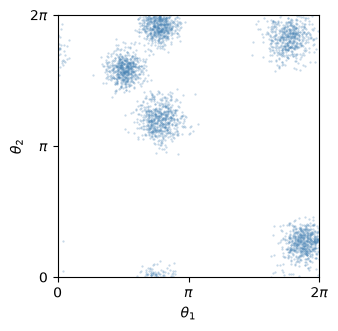

saved figures/klein_generated.pdf


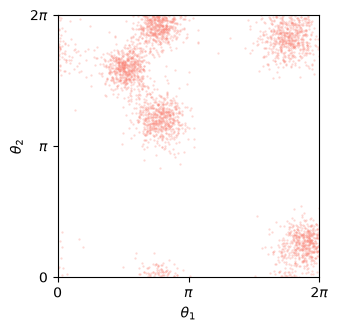

In [5]:
# ---- Klein bottle ----
gen_klein = cached_samples("klein")
if gen_klein is None:
    ck_klein = short_train("config/klein_bottle/splitting.yaml", "nb_klein", steps=6000)
    gen_klein = sample_splitting("config/klein_bottle/splitting.yaml", ck_klein, "/tmp/val/klein_gen.npy")
    save_samples("klein", gen_klein)
dat_klein = np.load("dataset/klein_bottle_2d_data.npy")

# Two separate, untitled, bbox-tight PDFs (data / generated) for the paper.
def _klein_panel(X, c, name):
    fig, a = plt.subplots(figsize=(3.4, 3.4))
    X = X[np.random.default_rng(0).permutation(len(X))[:3000]]   # data file is sorted by mode
    a.scatter(X[:, 0] % TWO_PI, X[:, 1] % TWO_PI, s=2.6, alpha=0.3, c=c, linewidths=0)
    a.set_xlim(0, TWO_PI); a.set_ylim(0, TWO_PI); a.set_aspect("equal")
    a.set_xticks([0, math.pi, TWO_PI]); a.set_yticks([0, math.pi, TWO_PI])
    a.set_xticklabels(["0", r"$\pi$", r"$2\pi$"]); a.set_yticklabels(["0", r"$\pi$", r"$2\pi$"])
    a.set_xlabel(r"$\theta_1$"); a.set_ylabel(r"$\theta_2$")
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    print(f"saved figures/{name}.pdf"); plt.show()

_klein_panel(dat_klein, "steelblue", "klein_data")
_klein_panel(gen_klein, "salmon", "klein_generated")

[rp2] loaded cached samples from notebook_cache/rp2_gen.npy
saved figures/rp2_data.pdf


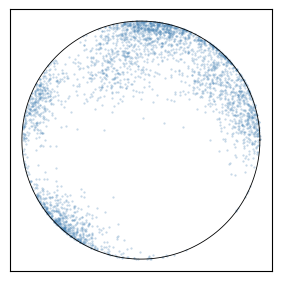

saved figures/rp2_generated.pdf


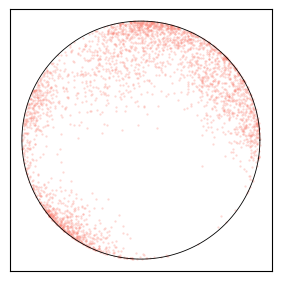

In [6]:
# ---- RP^2 ----
gen_rp2 = cached_samples("rp2")
if gen_rp2 is None:
    ck_rp2 = short_train("config/rp2/splitting.yaml", "nb_rp2", steps=20000)
    gen_rp2 = sample_splitting("config/rp2/splitting.yaml", ck_rp2, "/tmp/val/rp2_gen.npy")
    save_samples("rp2", gen_rp2)
dat_rp2 = np.load("dataset/rp2_gmm_data.npy")

def rp2_disk(X):   # upper-hemisphere disk projection (x,y); fold x_z<0 antipodally
    X = X.copy(); flip = X[:, 2] < 0; X[flip] = -X[flip]
    return X[:, 0], X[:, 1]

# Two separate, untitled, bbox-tight PDFs (data / generated).
th = np.linspace(0, TWO_PI, 200)
def _rp2_panel(X, c, name):
    fig, a = plt.subplots(figsize=(3.4, 3.4))
    u, v = rp2_disk(X[np.random.default_rng(0).permutation(len(X))[:3000]])   # data sorted by mode
    a.scatter(u, v, s=2.6, alpha=0.3, c=c, linewidths=0)
    a.plot(np.cos(th), np.sin(th), "k", lw=0.6)
    a.set_xlim(-1.1, 1.1); a.set_ylim(-1.1, 1.1); a.set_aspect("equal")
    a.set_xticks([]); a.set_yticks([])
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    print(f"saved figures/{name}.pdf"); plt.show()

_rp2_panel(dat_rp2, "steelblue", "rp2_data")
_rp2_panel(gen_rp2, "salmon", "rp2_generated")

**Reading Part 3.** With a short training run and a small network, the
splitting model reproduces the data modes on both the
Klein bottle (angle coordinates) and $\mathbb{RP}^2$ (hemisphere-disk
projection). The generated samples respect each surface's identifications,
confirming the framework trains correctly on non-orientable and non-Euclidean
surfaces using only the shipped configs.

## Part 4 — Training on a non-compact manifold: hyperbolic space $H^2$

Hyperbolic space is **non-compact** (infinite volume), so — unlike the compact
manifolds above — there is *no* uniform prior to diffuse toward. The framework
instead uses a **confining potential** $U(x)=\tfrac12\,d_H(x,o)^2/\sigma_x^2$,
whose Langevin stationary law is a *wrapped normal* centered at the origin $o$.
The splitting integrator adds $U$ as a symmetric Strang half-kick on the
velocity (a no-op on compact manifolds, so nothing else changes).

We realize $H^2$ on the Lorentz hyperboloid $\{x\in\mathbb R^3:\langle x,x\rangle_L=-1\}$
and visualize via the **Poincaré disk** map $(x_0,x_1,x_2)\mapsto(x_1,x_2)/(1+x_0)$.
Target data is a 4-component wrapped-normal mixture. We run a short training and
overlay generated points on the data.

[h2] loaded cached samples from notebook_cache/h2_gen.npy
saved figures/h2_data.pdf


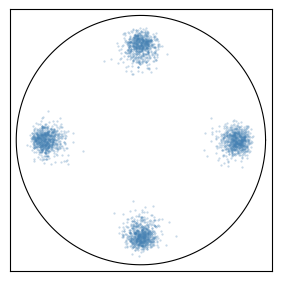

saved figures/h2_generated.pdf


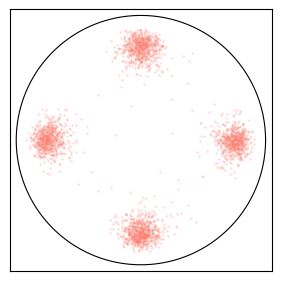

In [7]:
# H^2: same sampler script; the config carries the potential width. SDE sampler as for Klein / RP^2.
def sample_h2(ckpt, out, N=3000):
    cmd = ["%s" % sys.executable, "scripts/sample.py", "--ckpt", ckpt, "--out", out, "--no-infer_ode",
           "--N", str(N), "--config", "config/hyperbolic/splitting.yaml"]
    env = dict(os.environ, WANDB_MODE="offline")   # GPU: inherit CUDA_VISIBLE_DEVICES
    r = subprocess.run(cmd, env=env, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:]
    return np.load(out)

gen_h2 = cached_samples("h2")
if gen_h2 is None:
    ck_h2 = short_train("config/hyperbolic/splitting.yaml", "nb_h2", steps=3000)
    gen_h2 = sample_h2(ck_h2, "/tmp/val/h2_gen.npy")
    save_samples("h2", gen_h2)
dat_h2 = np.load("dataset/h2_wgmm.npy")

def to_poincare(X):
    X = X.reshape(-1, 3)
    return X[:, 1] / (1 + X[:, 0]), X[:, 2] / (1 + X[:, 0])

# Two separate, untitled, bbox-tight PDFs (data / generated).
th = np.linspace(0, TWO_PI, 200)
def _h2_panel(X, c, name):
    fig, a = plt.subplots(figsize=(3.4, 3.4))
    u, v = to_poincare(X[np.random.default_rng(0).permutation(len(X))[:3000]])
    a.scatter(u, v, s=2.6, alpha=0.3, c=c, linewidths=0)
    a.plot(np.cos(th), np.sin(th), "k", lw=0.8)   # disk boundary (infinity)
    a.set_xlim(-1.05, 1.05); a.set_ylim(-1.05, 1.05); a.set_aspect("equal")
    a.set_xticks([]); a.set_yticks([])
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    print(f"saved figures/{name}.pdf"); plt.show()

_h2_panel(dat_h2, "steelblue", "h2_data")
_h2_panel(gen_h2, "salmon", "h2_generated")

**Reading Part 4.** The generated points stay on the manifold (inside the
Poincaré disk — the boundary circle is infinity) and cluster at the four data
modes, confined by the potential rather than escaping to infinity. This shows the
splitting framework extends to **non-compact** geometry through the confining
potential, with no change to the rest of the pipeline.

---
### Summary

| Part | Claim | How it is shown |
|---|---|---|
| 1 | Forward process reaches the invariant law | $T^2$: $x_T\to$ Uniform (TV at the self-floor), $\mathrm{Var}(v_T)=\sigma^2$ |
| 2 | Target score is regular at interval left endpoints | single data point at origin: analytic score finite as $\delta\to0$; only the single-sample label variance diverges |
| 3 | Trains on non-orientable / non-Euclidean surfaces | Klein bottle and $\mathbb{RP}^2$ short runs recover the data modes |
| 4 | Trains on non-compact manifolds | $H^2$ with a confining potential recovers the data modes on the Poincaré disk |
